# Formativa 2 — Regresión logística para anticipar entregas atrasadas
## Dataset: *E-Commerce Shipping Data*

**MCDI501 - Estadística Computacional para la Toma de Decisiones**
Magíster en Ciencia de Datos e Inteligencia Artificial, Universidad Andrés Bello
Equipo: José Ignacio Rodríguez, Yerko Gallardo Miranda y Sebastián Rojas Araya

Este cuaderno ensaya el flujo completo de modelamiento predictivo que se usará en la Evaluación Sumativa 3 (S3). Parte de la pregunta de la Evaluación Sumativa 1 (S1), *¿qué características se asocian con el atraso y qué evidencia orienta una revisión operacional?*, y la lleva a un problema de clasificación: **anticipar si un envío llegará atrasado** (`entrega_atrasada = 1`) a partir de sus características. Las decisiones de modelamiento se apoyan explícitamente en los resultados de S1 y de la Evaluación Sumativa 2 (S2):

1. **Preparación de datos:** hallazgos de S1 y S2, valores faltantes simulados e imputados, outliers, partición 70/30 y estandarización.
2. **Regresión logística:** selección justificada de cuatro predictores, resumen del modelo, odds ratios, significancia, factor de inflación de la varianza (VIF) y confirmación de la selección con RFE.
3. **Desempeño predictivo:** matriz de confusión, métricas, curva ROC y área bajo la curva (AUC) en el conjunto de prueba, validación cruzada estratificada y búsqueda de hiperparámetros.
4. **Síntesis y reflexión** para S3.

## 0. Configuración, datos y semilla

Los datos se leen desde S1 (`sumativa_1/data/raw/ecommerce_shipping.csv`) y se verifica su huella SHA-256 contra el registro de S1, con los mismos nombres de variables y la misma codificación: `entrega_atrasada = 1` indica atraso y `0`, entrega puntual. Toda la aleatoriedad (simulación de faltantes y partición) usa la semilla registrada en S2 desde el *beacon* de aleatoriedad de la Universidad de Chile.

In [1]:
from pathlib import Path
import hashlib
import json
import platform

import numpy as np
import pandas as pd
import scipy
import sklearn
import statsmodels
import statsmodels.api as sm
from scipy import stats
from IPython.display import display

# Raíz del repositorio: funciona al ejecutar desde el repositorio, formativa_2/ o sus notebooks/
ubicacion = Path.cwd().resolve()
REPO = next((p for p in [ubicacion, *ubicacion.parents]
             if (p / 'formativa_2/notebooks/formativa_2_grupo1.ipynb').is_file()), None)
if REPO is None:
    raise FileNotFoundError('Ejecute desde el repositorio, formativa_2/ o sus notebooks/.')
RAIZ, S1, S2 = REPO / 'formativa_2', REPO / 'sumativa_1', REPO / 'sumativa_2'
TABLAS, FIGURAS = RAIZ / 'outputs/tablas', RAIZ / 'outputs/figuras'
for carpeta in (TABLAS, FIGURAS):
    carpeta.mkdir(parents=True, exist_ok=True)

# Datos: el CSV debe ser el registrado en S1
DATOS = S1 / 'data/raw/ecommerce_shipping.csv'
registro_fuente = json.loads((S1 / 'docs/registro_fuente.json').read_text(encoding='utf-8'))
HUELLA_DATOS = hashlib.sha256(DATOS.read_bytes()).hexdigest()
assert HUELLA_DATOS in {registro_fuente['file']['sha256'], registro_fuente['file']['sha256_lf_normalized']}, \
    'El CSV no coincide con el registrado en S1.'
raw = pd.read_csv(DATOS, encoding='utf-8-sig')
NOMBRES = {
    'ID': 'id_envio', 'Warehouse_block': 'bloque_bodega', 'Mode_of_Shipment': 'modalidad_envio',
    'Customer_care_calls': 'llamadas_atencion', 'Customer_rating': 'calificacion_cliente',
    'Cost_of_the_Product': 'costo_producto', 'Prior_purchases': 'compras_previas',
    'Product_importance': 'importancia_producto', 'Gender': 'genero',
    'Discount_offered': 'descuento_ofrecido', 'Weight_in_gms': 'peso_gramos',
}
TARGET = 'entrega_atrasada'
df = raw.rename(columns=NOMBRES)
df[TARGET] = raw['Reached.on.Time_Y.N']
n, n_atr = len(df), int(df[TARGET].sum())
assert (n, n_atr, n - n_atr) == (10_999, 6_563, 4_436), 'Los conteos no coinciden con S1.'

# Semilla de S2 (beacon de la Universidad de Chile), verificada contra su pulso
registro_semilla = json.loads((S2 / 'docs/registro_semilla.json').read_text(encoding='utf-8'))
SEMILLA = registro_semilla['semilla']
assert SEMILLA == int(registro_semilla['pulso']['outputValue'], 16) % 2**32
# S2 usó los 7 primeros hijos de SeedSequence(SEMILLA); la Formativa 2 usa el octavo para los faltantes
RNG_FALTANTES = np.random.default_rng(np.random.SeedSequence(SEMILLA).spawn(8)[7])

VERSIONES = dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__, scipy=scipy.__version__,
                 statsmodels=statsmodels.__version__, sklearn=sklearn.__version__)
print(f'Datos: {DATOS.relative_to(REPO).as_posix()} (SHA-256 {HUELLA_DATOS[:12]}…)')
print(f'{n:,} envíos | atrasados: {n_atr:,} ({n_atr / n:.2%}) | puntuales: {n - n_atr:,}'.replace(',', '.'))
print(f'SEMILLA = {SEMILLA} | ' + ', '.join(f'{k} {v}' for k, v in VERSIONES.items()))

Datos: sumativa_1/data/raw/ecommerce_shipping.csv (SHA-256 dcdc3fd8f050…)
10.999 envíos | atrasados: 6.563 (59.67%) | puntuales: 4.436
SEMILLA = 1505514103 | python 3.14.4, numpy 2.5.3, pandas 3.0.6, scipy 1.18.1, statsmodels 0.15.0, sklearn 1.9.1


In [2]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

# Convención de figuras de S1 y S2: negro = referencia; azul = modelo; terracota = destacado; gris punteado = umbrales
AZUL, TERRA, GRIS, GRID = '#1f5f8b', '#d1603d', '#555555', '#e1e4e8'
ANCHO = 6.3
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'savefig.bbox': 'tight', 'pdf.fonttype': 42,
    'figure.constrained_layout.use': True, 'font.family': 'serif', 'font.size': 9,
    'axes.titlesize': 9, 'axes.labelsize': 8.5, 'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.fontsize': 8, 'legend.frameon': False, 'axes.edgecolor': '#8c8578',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlelocation': 'left',
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
})


def num(x, dec=0):
    # Formato es-CL: punto de miles, coma decimal y signo menos tipográfico
    return f'{x:,.{dec}f}'.replace(',', '_').replace('.', ',').replace('_', '.').replace('-', '−')


def guardar(nombre, fig):
    for ext in ('pdf', 'png'):
        fig.savefig(FIGURAS / f'{nombre}.{ext}')
    plt.show()

## 1. Hallazgos previos de S1 y S2

Los resultados se leen directamente desde las tablas publicadas en S1 (`sumativa_1/outputs/tablas/`) y S2 (`sumativa_2/outputs/`), para que cada decisión sea trazable:

- **S1:** calidad de datos (faltantes y extremos según el rango intercuartílico, IQR), distribución de cada variable, correlación con el atraso y contrastes de hipótesis.
- **S2:** intervalos de confianza (IC) *bootstrap* de las correlaciones, su estabilidad en los escenarios de sensibilidad (winsorización, exclusión IQR y descuento ≤ 10), parámetros robustos y el estado de cada resultado validado.

In [3]:
T1, T2 = S1 / 'outputs/tablas', S2 / 'outputs'
calidad_s1 = pd.read_csv(T1 / 'calidad_datos.csv')
descriptiva_s1 = pd.read_csv(T1 / 'descriptiva_cuantitativas.csv', index_col=0)
cor_s1 = pd.read_csv(T1 / 'correlacion_dependiente_cuantitativas.csv').set_index('variable')
holm_s1 = pd.read_csv(T1 / 'contrastes_holm_7.csv').set_index('codigo')
cor_s2 = pd.read_csv(T2 / 'tablas/correlaciones_bootstrap.csv').set_index('id')
sens_s2 = pd.read_csv(T2 / 'tablas/sensibilidad_correlaciones.csv')
validados_s2 = pd.read_csv(T2 / 'resultados_validados.csv').set_index('id')
param_s2 = pd.read_csv(T2 / 'tablas/bootstrap_parametros.csv').set_index('id')

# Identificador de cada correlación con el atraso en S2
ID_COR_S2 = {'descuento_ofrecido': 'COR-1', 'peso_gramos': 'COR-2', 'costo_producto': 'COR-4', 'compras_previas': 'COR-5'}
extremos = calidad_s1[calidad_s1['control'] == 'extremos_regla_IQR'].set_index('variable')['observado']
le10 = sens_s2[sens_s2['escenario'] == 'descuento_le10'].set_index('id')
filas = []
for v in ['peso_gramos', 'descuento_ofrecido', 'costo_producto', 'compras_previas', 'llamadas_atencion']:
    i = ID_COR_S2.get(v)
    filas.append({
        'variable': v,
        'r_pb_S1': cor_s1.loc[v, 'r_punto_biserial'], 'p_S1': cor_s1.loc[v, 'p_punto_biserial'],
        'asimetria_S1': descriptiva_s1.loc[v, 'asimetria'], 'extremos_IQR_S1': extremos.get(v),
        'IC_bootstrap_S2': f"[{cor_s2.loc[i, 'ic_inf']:.3f}; {cor_s2.loc[i, 'ic_sup']:.3f}]" if i else '—',
        'r_descuento_le10_S2': f"{le10.loc[i, 'estimacion']:.3f} [{le10.loc[i, 'ic_inf']:.3f}; {le10.loc[i, 'ic_sup']:.3f}]" if i else '—',
        'estado_S2': validados_s2.loc[i, 'estado'] if i else 'no evaluada en S2',
    })
hallazgos = pd.DataFrame(filas).set_index('variable')
hallazgos.to_csv(TABLAS / 'hallazgos_s1_s2.csv')
print('Variables cuantitativas: correlación con el atraso (S1) y validación (S2)')
display(hallazgos.round(4))
print('Contrastes de S1 con su valor p ajustado por Holm')
display(holm_s1[['prueba', 'p_holm', 'decision_holm']])
print('Parámetros de S1 validados por bootstrap en S2 (IC BCa)')
display(param_s2[['parametro', 'estimacion_s1', 'ic_s1_inf', 'ic_s1_sup', 'ic_bca_inf', 'ic_bca_sup']].round(4))
print('Calidad de datos de S1 (faltantes y extremos)')
display(calidad_s1[calidad_s1['control'].isin(['nulos_totales', 'extremos_regla_IQR'])][['control', 'variable', 'observado', 'detalle']])

Variables cuantitativas: correlación con el atraso (S1) y validación (S2)


,r_pb_S1,p_S1,asimetria_S1,extremos_IQR_S1,IC_bootstrap_S2,r_descuento_le10_S2,estado_S2
variable,,,,,,,
peso_gramos,-0.2688,0.0,-0.2497,bajo=0; alto=0,[-0.287; -0.251],-0.088 [-0.109; -0.066],"respaldado, magnitud sensible"
descuento_ofrecido,0.3971,0.0,1.7989,bajo=0; alto=2209,[0.388; 0.407],-0.014 [-0.036; 0.007],sensible
costo_producto,-0.0736,0.0,-0.1571,bajo=0; alto=0,[-0.092; -0.055],0.003 [-0.018; 0.025],sensible
compras_previas,-0.0555,0.0,1.6819,bajo=0; alto=1003,[-0.075; -0.037],-0.012 [-0.033; 0.010],sensible
llamadas_atencion,-0.0671,0.0,0.3919,bajo=0; alto=0,—,—,no evaluada en S2


Contrastes de S1 con su valor p ajustado por Holm


,prueba,p_holm,decision_holm
codigo,,,
T01,Chi-cuadrado: modalidad y atraso,6.895488e-01,no se rechaza H0
T02,Welch: peso medio atrasadas vs puntuales,9.654651e-180,se rechaza H0
T03,Welch: descuento medio atrasadas vs puntuales,0.000000e+00,se rechaza H0
E1,Mann-Whitney U: peso atrasadas vs puntuales,1.359519e-170,se rechaza H0
E2,z dos proporciones: atraso importancia alta vs...,9.795259e-04,se rechaza H0
E3,z dos proporciones: atraso descuento > 10 vs <...,0.000000e+00,se rechaza H0
E4,Welch: costo medio atrasadas vs puntuales,3.107184e-14,se rechaza H0


Parámetros de S1 validados por bootstrap en S2 (IC BCa)


,parametro,estimacion_s1,ic_s1_inf,ic_s1_sup,ic_bca_inf,ic_bca_sup
id,,,,,,
PAR-1,Proporción de atraso,0.5967,0.5875,0.6058,0.5875,0.6059
PAR-2,Peso medio,3634.0167,3603.4508,3664.5826,3602.7570,3665.2821
PAR-3,Costo medio,210.1968,209.2985,211.0952,209.3138,211.1132
PAR-4,Llamadas medias,4.0545,4.0331,4.0758,4.0337,4.0755
EFE-1,Diferencia de peso medio (atrasado − puntual),-896.0283,-956.0308,-836.0258,-955.4048,-836.5055


Calidad de datos de S1 (faltantes y extremos)


,control,variable,observado,detalle
1,nulos_totales,todas,0,Sin imputación ni faltantes artificiales
14,extremos_regla_IQR,llamadas_atencion,bajo=0; alto=0,NaN
16,extremos_regla_IQR,costo_producto,bajo=0; alto=0,NaN
18,extremos_regla_IQR,compras_previas,bajo=0; alto=1003,Valores válidos; no se eliminan
20,extremos_regla_IQR,descuento_ofrecido,bajo=0; alto=2209,Valores válidos; no se eliminan
22,extremos_regla_IQR,peso_gramos,bajo=0; alto=0,NaN


#### Qué se toma de S1 y S2

| Hallazgo | Fuente | Decisión en este modelo |
|---|---|---|
| No hay valores faltantes (0 nulos en 10.999 envíos) | S1, calidad de datos | Se simulan faltantes MCAR para ensayar la imputación (2.1) |
| Extremos IQR válidos en descuento (2.209) y compras previas (1.003); asimetría de 1,80 y 1,68 | S1 | Se conservan; se imputa con la mediana, robusta a la asimetría (2.1 y 2.2) |
| Correlaciones con el atraso: descuento 0,397; peso −0,269; costo −0,074; compras previas −0,056; llamadas −0,067 | S1 | Candidatas a predictor, en ese orden de fuerza |
| IC *bootstrap* de esas correlaciones: ninguno incluye el cero con los datos completos | S2 | Las cuatro tienen un signo bien determinado |
| Solo el peso conserva su correlación lejos del cero con descuento ≤ 10 (−0,088); las demás pasan a incluir el cero | S2, sensibilidad | El peso es el predictor robusto; el resto depende del segmento > 10 (3.1 y 4.3) |
| Parámetros robustos: los IC BCa coinciden con los de S1 (anchos ±2,3 %) | S2 | La proporción de atraso de 59,67 % es una línea base confiable (4.1) |
| Modalidad sin asociación (T01, *p* de Holm = 0,69) | S1 y S2 | Se excluye (2.3) |
| Los envíos 1 a 3.135 están todos atrasados | S2, *jackknife* | Se excluye el identificador (2.3) |

## 2. Preparación de datos

### 2.1 Valores faltantes: simulación completamente al azar (MCAR) e imputación

S1 verificó que la base **no tiene valores faltantes** (`nulos_totales = 0`). Para ensayar una regla de imputación, como se hará en S3 si aparecen faltantes, se **simulan valores faltantes completamente al azar** (*Missing Completely At Random*, MCAR) sobre una copia de los datos; el CSV original no se modifica.

- **Mecanismo:** en cada uno de los cuatro predictores numéricos del modelo se enmascara exactamente el 5 % de los envíos (550), elegidos al azar y de forma independiente entre variables. La probabilidad de faltar no depende del atraso ni de ningún valor, lo que define MCAR.
- **Verificación:** la proporción de faltantes no debe diferir entre envíos atrasados y puntuales (prueba χ² por variable), y la proporción de envíos con al menos un faltante debe acercarse a $1 - 0{,}95^4 = 18{,}5\%$.

In [4]:
PREDICTORES = ['peso_gramos', 'descuento_ofrecido', 'costo_producto', 'compras_previas']
assert df.isna().sum().sum() == 0, 'S1 no registró faltantes: la base original debe estar completa.'
TASA_MCAR = 0.05

df_mcar = df.copy()
for v in PREDICTORES:   # 550 envíos por variable, elegidos al azar y de forma independiente
    filas_nulas = RNG_FALTANTES.choice(n, size=round(TASA_MCAR * n), replace=False)
    df_mcar.loc[df_mcar.index[filas_nulas], v] = np.nan

filas = []
for v in PREDICTORES:
    falta = df_mcar[v].isna()
    tabla = pd.crosstab(falta, df_mcar[TARGET])
    filas.append({'variable': v, 'faltantes': int(falta.sum()), 'pct_faltantes': falta.mean(),
                  'pct_en_atrasados': falta[df_mcar[TARGET] == 1].mean(),
                  'pct_en_puntuales': falta[df_mcar[TARGET] == 0].mean(),
                  'p_chi2_independencia_atraso': stats.chi2_contingency(tabla)[1]})
faltantes = pd.DataFrame(filas).set_index('variable')
con_faltante = df_mcar[PREDICTORES].isna().any(axis=1)
assert (faltantes['faltantes'] == 550).all() and df[PREDICTORES].notna().all().all()   # el original no cambia
faltantes.to_csv(TABLAS / 'faltantes_mcar.csv')
print(f'Envíos con al menos un faltante: {num(con_faltante.sum())} ({num(con_faltante.mean() * 100, 1)}%; '
      f'esperado bajo independencia: {num((1 - 0.95 ** 4) * 100, 1)}%)')
display(faltantes.round(4))

Envíos con al menos un faltante: 2.039 (18,5%; esperado bajo independencia: 18,5%)


,faltantes,pct_faltantes,pct_en_atrasados,pct_en_puntuales,p_chi2_independencia_atraso
variable,,,,,
peso_gramos,550,0.05,0.0486,0.0521,0.4389
descuento_ofrecido,550,0.05,0.0469,0.0546,0.0793
costo_producto,550,0.05,0.0477,0.0534,0.1905
compras_previas,550,0.05,0.0503,0.0496,0.9063


**Regla de imputación: mediana del conjunto de entrenamiento.**

- **Por qué imputar y no eliminar filas.** Bajo MCAR, eliminar los envíos con algún faltante no sesga los coeficientes, pero descartaría cerca del 18,5 % de la muestra. Además, en producción no se podría predecir un envío que llegue con un dato faltante. Una imputación simple conserva todos los envíos.
- **Por qué la mediana y no la media.** S1 mostró que el descuento y las compras previas son muy asimétricos, con 2.209 y 1.003 extremos IQR válidos que se conservan, y que el peso es bimodal. La mediana no se desplaza con esos extremos.
- **Sin fuga de información.** La mediana se calcula **solo con el conjunto de entrenamiento**, después de la partición, y se aplica igual al de prueba. Así el conjunto de prueba no influye en ninguna decisión del modelo.
- **Costo conocido.** Imputar un valor constante reduce la varianza y atenúa las correlaciones. La sección 4.3 compara el modelo imputado con el de casos completos y con el ajustado a los datos originales sin faltantes.

### 2.2 Outliers

**Se conservan todos los envíos.**

- S1 identificó extremos IQR en el descuento (2.209) y en las compras previas (1.003), y los clasificó como valores válidos.
- S2 mostró que **winsorizar** peso y costo al 1/99 % no cambia ninguna estimación, prueba ni correlación.
- **Excluir** los extremos IQR (3.028 envíos) cambia la población: la tasa de atraso baja de 59,7 % a 49,5 %.

Eliminar outliers no mejoraría el modelo y sí cambiaría la población a la que se aplica.

### 2.3 Variables excluidas antes de modelar

| Variable | Motivo (S1 y S2) |
|---|---|
| `id_envio` | **Fuga de información.** S2 encontró que los envíos 1 a 3.135 están todos atrasados: el identificador "predeciría" el atraso por el orden del archivo, no por una característica del envío. |
| Llamadas a atención y calificación | **Temporalidad.** S1 advirtió que pueden registrarse después de la entrega; usarlas para anticipar un atraso sería usar información del futuro. |
| Modalidad de envío | La prueba χ² de independencia entre modalidad de envío y atraso (T01) no rechazó la independencia (*p* de Holm = 0,69), y la permutación de S2 lo confirmó. |
| Indicador "descuento > 10" | **Separación completa:** los 2.647 envíos con descuento > 10 están todos atrasados, por lo que su coeficiente de máxima verosimilitud no existe (tiende a infinito). Se usa el descuento continuo. |

### 2.4 Partición 70/30 y estandarización

La partición es **estratificada** por el atraso, para que entrenamiento y prueba conserven la proporción de 59,7 %, y usa la semilla de S2. Los cuatro predictores se **estandarizan** (media 0 y desviación estándar 1), con parámetros calculados solo en el entrenamiento. Así los coeficientes son comparables entre variables con escalas muy distintas: gramos, USD y unidades de descuento.

In [5]:
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X, y = df_mcar[PREDICTORES], df_mcar[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEMILLA)
particion = pd.DataFrame({'envios': [len(y_train), len(y_test)], 'tasa_atraso': [y_train.mean(), y_test.mean()],
                          'con_faltante': [X_train.isna().any(axis=1).mean(), X_test.isna().any(axis=1).mean()]},
                         index=['entrenamiento', 'prueba'])
assert (len(y_train), len(y_test)) == (7_699, 3_300)
assert abs(y_train.mean() - y_test.mean()) < 0.005, 'La estratificación debe conservar la tasa de atraso.'

# Imputación por mediana y estandarización: ambas ajustadas SOLO con el entrenamiento
preparacion = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
X_train_s = pd.DataFrame(preparacion.fit_transform(X_train), columns=PREDICTORES, index=X_train.index)
X_test_s = pd.DataFrame(preparacion.transform(X_test), columns=PREDICTORES, index=X_test.index)
imputador, escalador = preparacion.named_steps['simpleimputer'], preparacion.named_steps['standardscaler']
assert np.allclose(imputador.statistics_, X_train.median()), 'La mediana debe venir solo del entrenamiento.'
assert X_train_s.notna().all().all() and X_test_s.notna().all().all()

parametros_prep = pd.DataFrame({'mediana_imputacion': imputador.statistics_, 'media_escalado': escalador.mean_,
                                'de_escalado': escalador.scale_}, index=PREDICTORES)
particion.to_csv(TABLAS / 'particion.csv')
parametros_prep.to_csv(TABLAS / 'parametros_preparacion.csv')
display(particion.round(4))
display(parametros_prep.round(2))
print('Entrenamiento estandarizado (media ≈ 0, DE ≈ 1):')
display(X_train_s.describe().loc[['mean', 'std']].round(3))

,envios,tasa_atraso,con_faltante
entrenamiento,7699,0.5967,0.1805
prueba,3300,0.5967,0.1967


,mediana_imputacion,media_escalado,de_escalado
peso_gramos,4147.0,3660.81,1599.21
descuento_ofrecido,7.0,13.08,15.89
costo_producto,214.0,210.47,47.15
compras_previas,3.0,3.54,1.48


Entrenamiento estandarizado (media ≈ 0, DE ≈ 1):


,peso_gramos,descuento_ofrecido,costo_producto,compras_previas
mean,-0.0,0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0


## 3. Modelo de regresión logística

### 3.1 Selección de predictores

Se seleccionan **cuatro predictores**. Cada uno se justifica con un resultado de S1 y su validación en S2:

| Predictor | Evidencia de S1 | Validación en S2 | Rol en el modelo |
|---|---|---|---|
| **Peso** (g) | Diferencia de −896 g entre atrasados y puntuales (prueba *t* de Welch de peso medio entre envíos atrasados y puntuales, T02); r = −0,269 | **Respaldado:** único predictor cuya correlación excluye el cero en todos los escenarios, incluido descuento ≤ 10 (−0,088) | Predictor principal y robusto |
| **Descuento** | Correlación más fuerte con el atraso (r = 0,397); diferencia de 13,1 unidades (prueba *t* de Welch de descuento medio entre envíos atrasados y puntuales, T03) | **Sensible:** su asociación existe solo por el segmento > 10; con descuento ≤ 10 es −0,014, con un IC que incluye el cero | Se incluye **continuo** por su poder predictivo, y se evalúa críticamente en la sección 4.3 |
| **Costo** (USD) | r = −0,074; diferencia significativa de costo medio | **Sensible:** débil; su IC incluye el cero al excluir extremos o el segmento > 10 | Control; se evalúa si aporta |
| **Compras previas** | r = −0,056 | **Sensible:** débil e inestable fuera del segmento > 10 | Control; se evalúa si aporta |

Con cuatro predictores, cada coeficiente se estima con más de 1.100 eventos de la clase menos frecuente (puntuales) por predictor. Además, S2 mostró que la correlación más alta entre ellos, descuento–peso con ρ = −0,316, no hace prever multicolinealidad severa; la sección 3.3 lo verifica con el VIF.

### 3.2 Ajuste e interpretación

El modelo es $\log\frac{P(\text{atraso})}{1-P(\text{atraso})} = \beta_0 + \sum_j \beta_j z_j$, donde $z_j$ es el predictor estandarizado. Se ajusta por máxima verosimilitud con `statsmodels.Logit` en el conjunto de entrenamiento. El **odds ratio** (OR) $e^{\beta_j}$ indica por cuánto se multiplican las chances de atraso al aumentar el predictor en **una desviación estándar (DE)**, manteniendo constantes los demás. También se informa en unidades naturales del negocio.

In [6]:
modelo = sm.Logit(y_train, sm.add_constant(X_train_s)).fit(disp=0)
assert modelo.mle_retvals['converged'], 'El modelo no convergió.'
print(modelo.summary2(title='Regresión logística: entrega atrasada ~ peso + descuento + costo + compras previas'))

# Odds ratios por 1 DE y en unidades naturales: OR_unidad = exp(beta * unidad / DE_entrenamiento)
UNIDAD = {'peso_gramos': (1_000, '1.000 g'), 'descuento_ofrecido': (10, '10 unidades'),
          'costo_producto': (10, '10 USD'), 'compras_previas': (1, '1 compra')}
ic = modelo.conf_int()
filas = []
for v in PREDICTORES:
    factor = UNIDAD[v][0] / escalador.scale_[PREDICTORES.index(v)]
    filas.append({'predictor': v, 'coef': modelo.params[v], 'ee': modelo.bse[v], 'z': modelo.tvalues[v], 'p': modelo.pvalues[v],
                  'or_1de': np.exp(modelo.params[v]), 'or_1de_inf': np.exp(ic.loc[v, 0]), 'or_1de_sup': np.exp(ic.loc[v, 1]),
                  'unidad': UNIDAD[v][1], 'or_unidad': np.exp(modelo.params[v] * factor),
                  'or_unidad_inf': np.exp(ic.loc[v, 0] * factor), 'or_unidad_sup': np.exp(ic.loc[v, 1] * factor),
                  'de_entrenamiento': escalador.scale_[PREDICTORES.index(v)]})
coeficientes = pd.DataFrame(filas).set_index('predictor')
resumen_ajuste = pd.Series({'n_entrenamiento': int(modelo.nobs), 'log_verosimilitud': modelo.llf, 'log_verosimilitud_nulo': modelo.llnull,
                            'pseudo_r2_mcfadden': modelo.prsquared, 'p_razon_verosimilitud': modelo.llr_pvalue,
                            'aic': modelo.aic, 'intercepto': modelo.params['const'], 'odds_base': np.exp(modelo.params['const'])})
coeficientes.to_csv(TABLAS / 'coeficientes_odds_ratios.csv')
resumen_ajuste.to_csv(TABLAS / 'resumen_ajuste.csv', header=['valor'])
display(coeficientes.drop(columns='de_entrenamiento').round(4))
display(resumen_ajuste.to_frame('valor').round(4))

Regresión logística: entrega atrasada ~ peso + descuento + costo + compras previas
Model:               Logit             Method:            MLE      
Dependent Variable:  entrega_atrasada  Pseudo R-squared:  0.179    
Date:                2026-10-22 21:45  AIC:               8534.7609
No. Observations:    7699              BIC:               8569.5052
Df Model:            4                 Log-Likelihood:    -4262.4  
Df Residuals:        7694              LL-Null:           -5191.6  
Converged:           1.0000            LLR p-value:       0.0000   
No. Iterations:      8.0000            Scale:             1.0000   
-------------------------------------------------------------------
                    Coef.  Std.Err.    z     P>|z|   [0.025  0.975]
-------------------------------------------------------------------
const               0.9204   0.0442  20.8295 0.0000  0.8338  1.0070
peso_gramos        -0.3263   0.0290 -11.2655 0.0000 -0.3830 -0.2695
descuento_ofrecido  1.8228   0.08

,coef,ee,z,p,or_1de,or_1de_inf,or_1de_sup,unidad,or_unidad,or_unidad_inf,or_unidad_sup
predictor,,,,,,,,,,,
peso_gramos,-0.3263,0.0290,-11.2655,0.0,0.7216,0.6818,0.7638,1.000 g,0.8154,0.7870,0.8449
descuento_ofrecido,1.8228,0.0859,21.2109,0.0,6.1891,5.2297,7.3245,10 unidades,3.1492,2.8324,3.5013
costo_producto,-0.1278,0.0275,-4.6405,0.0,0.8800,0.8338,0.9288,10 USD,0.9733,0.9622,0.9845
compras_previas,-0.1292,0.0272,-4.7457,0.0,0.8788,0.8331,0.9270,1 compra,0.9166,0.8842,0.9502


,valor
n_entrenamiento,7699.0000
log_verosimilitud,-4262.3805
log_verosimilitud_nulo,-5191.6412
pseudo_r2_mcfadden,0.1790
p_razon_verosimilitud,0.0000
aic,8534.7609
intercepto,0.9204
odds_base,2.5104


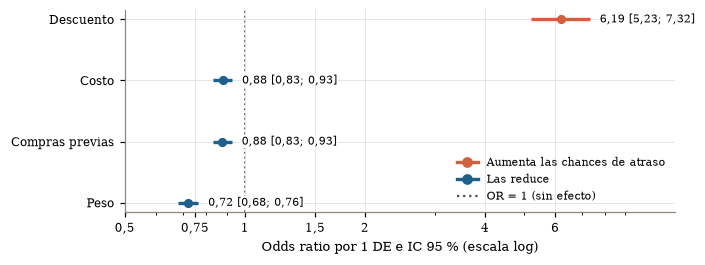

In [7]:
ETIQ = {'peso_gramos': 'Peso', 'descuento_ofrecido': 'Descuento', 'costo_producto': 'Costo', 'compras_previas': 'Compras previas'}
fig, ax = plt.subplots(figsize=(ANCHO, 2.3))
orden = coeficientes.sort_values('or_1de').index
for k, v in enumerate(orden):
    fila = coeficientes.loc[v]
    color = TERRA if fila['or_1de'] > 1 else AZUL
    ax.hlines(k, fila['or_1de_inf'], fila['or_1de_sup'], color=color, lw=2.2)
    ax.plot(fila['or_1de'], k, 'o', color=color, ms=5)
    ax.text(fila['or_1de_sup'] * 1.06, k, f"{num(fila['or_1de'], 2)} [{num(fila['or_1de_inf'], 2)}; {num(fila['or_1de_sup'], 2)}]",
            va='center', fontsize=7.5, bbox=dict(facecolor='white', edgecolor='none', pad=0.5))
ax.axvline(1, color=GRIS, ls=':', lw=1.2, zorder=0)
ax.set_xscale('log')
ax.set_xticks([0.5, 0.75, 1, 1.5, 2, 4, 6], ['0,5', '0,75', '1', '1,5', '2', '4', '6'])
ax.set_xlim(0.5, 12)
ax.set_yticks(range(len(orden)), [ETIQ[v] for v in orden])
ax.set_xlabel('Odds ratio por 1 DE e IC 95 % (escala log)')
ax.legend([Line2D([], [], color=TERRA, marker='o', lw=2.2), Line2D([], [], color=AZUL, marker='o', lw=2.2),
           Line2D([], [], color=GRIS, ls=':')], ['Aumenta las chances de atraso', 'Las reduce', 'OR = 1 (sin efecto)'],
          loc='lower right', fontsize=7)
guardar('fig_1_odds_ratios', fig)

#### Interpretación de coeficientes, odds ratios y significancia

| Predictor | β (EE) | OR por 1 DE [IC 95 %] | OR en unidades naturales [IC 95 %] | Lectura |
|---|---:|---:|---:|---|
| Peso | −0,326 (0,029) | 0,72 [0,68; 0,76] | 0,82 por 1.000 g [0,79; 0,84] | Cada kilo adicional reduce las chances de atraso en ≈ 18 % |
| Descuento | 1,823 (0,086) | 6,19 [5,23; 7,32] | 3,15 por 10 unidades [2,83; 3,50] | Cada 10 unidades de descuento triplican las chances de atraso |
| Costo | −0,128 (0,028) | 0,88 [0,83; 0,93] | 0,973 por 10 USD [0,962; 0,985] | Efecto pequeño: −2,7 % de chances por cada 10 USD |
| Compras previas | −0,129 (0,027) | 0,88 [0,83; 0,93] | 0,917 por compra [0,884; 0,950] | Cada compra previa reduce las chances en ≈ 8 % |

**Dirección coherente con S1.** Los cuatro signos coinciden con las correlaciones de S1: más descuento se asocia con más atraso; más peso, costo y compras previas, con menos. El intercepto (0,920) da chances de 2,51 a 1 (probabilidad de 72 %) para un envío con los cuatro predictores en su media.

**Significancia.** Los cuatro coeficientes tienen *p* < 0,001 (|*z*| entre 4,6 y 21,2), y la razón de verosimilitudes rechaza que el modelo equivalga al nulo (*p* < 0,001). Con 7.699 envíos, sin embargo, también los efectos pequeños resultan significativos. La **magnitud** distingue lo relevante:

- el descuento domina (OR de 6,2 por DE);
- el peso tiene un efecto moderado (0,72);
- costo y compras previas son débiles (0,88), como anticipó S2 al clasificarlos como sensibles.

**Efecto ajustado frente a crudo.** El OR del peso es 0,72 con descuento en el modelo y 0,53 sin él (sección 4.3). Parte de la asociación cruda del peso con el atraso pasa por el descuento, porque los envíos con descuento alto son más livianos (ρ = −0,316 en S2). Por eso S2 recomendaba modelarlos juntos.

**Ajuste global.** El pseudo-R² de McFadden es 0,179. Valores entre 0,2 y 0,4 indican un ajuste muy bueno (McFadden, 1979), así que el modelo explica una parte relevante, aunque no dominante, de la verosimilitud.

### 3.3 Diagnóstico de multicolinealidad (VIF)

El factor de inflación de la varianza (VIF) de cada predictor es $1/(1-R_j^2)$, donde $R_j^2$ proviene de regresionar ese predictor sobre los demás. Indica cuánto se infla la varianza de su coeficiente por estar correlacionado con los otros. Criterio: VIF < 5 sin problema; 5–10 moderado; > 10 severo.

In [8]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = sm.add_constant(X_train_s)
vif = pd.DataFrame({'vif': [variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])]},
                   index=PREDICTORES)
vif['r2_con_otros'] = 1 - 1 / vif['vif']
vif['diagnostico'] = np.where(vif['vif'] < 5, 'sin problema', np.where(vif['vif'] < 10, 'moderado', 'severo'))
vif.to_csv(TABLAS / 'vif.csv')
display(vif.round(3))
print('Correlaciones entre predictores (entrenamiento, después de imputar):')
display(X_train_s.corr().round(3))
assert (vif['vif'] < 5).all()

,vif,r2_con_otros,diagnostico
peso_gramos,1.248,0.198,sin problema
descuento_ofrecido,1.222,0.182,sin problema
costo_producto,1.062,0.059,sin problema
compras_previas,1.061,0.057,sin problema


Correlaciones entre predictores (entrenamiento, después de imputar):


,peso_gramos,descuento_ofrecido,costo_producto,compras_previas
peso_gramos,1.000,-0.364,-0.134,-0.168
descuento_ofrecido,-0.364,1.000,-0.128,-0.084
costo_producto,-0.134,-0.128,1.000,0.118
compras_previas,-0.168,-0.084,0.118,1.000


#### Interpretación del VIF

Los cuatro VIF están entre **1,06 y 1,25**, muy por debajo del umbral de 5: **no hay multicolinealidad**. El mayor corresponde al peso y al descuento, cuya correlación en el entrenamiento es −0,36, coherente con el ρ = −0,316 que reportó S2. Un VIF de 1,25 significa que la varianza del coeficiente del peso se infla solo un 25 % por compartir información con los demás. Los EE y los IC de la tabla anterior son confiables, y los OR pueden interpretarse como efectos ajustados. No fue necesario eliminar ni combinar variables.

### 3.4 Confirmación automática de la selección (RFE)

La **eliminación recursiva de características** (*Recursive Feature Elimination*, RFE) ajusta una regresión logística, elimina el predictor con el menor |coeficiente| estandarizado y repite el proceso hasta quedarse con *k* variables. Se usa para **confirmar** la selección analítica, no para reemplazarla. Todo se calcula **solo en el entrenamiento**, con la misma imputación por mediana y la misma estandarización:

1. **Conjunto analítico** (los cuatro predictores): ¿en qué orden los elimina RFE para *k* = 1, 2, 3 y 4?
2. **Todos los candidatos admisibles** (todas las columnas salvo `id_envio`, con las categóricas en *dummies*): RFE con validación cruzada (RFECV) elige el número de variables que maximiza el AUC en una validación cruzada estratificada de 10 particiones.

In [9]:
from sklearn.compose import make_column_transformer
from sklearn.feature_selection import RFE, RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import OneHotEncoder

CV10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEMILLA)
logit_sk = LogisticRegression(C=np.inf, max_iter=1_000)   # sin penalización, como el Logit de statsmodels

# 1) Orden de eliminación dentro del conjunto analítico
Z_train = preparacion.transform(X_train)   # misma imputación y escalado, ya ajustados con el entrenamiento
filas = []
for k in range(1, len(PREDICTORES) + 1):
    rfe = RFE(logit_sk, n_features_to_select=k).fit(Z_train, y_train)
    filas.append({'k': k, 'variables': ', '.join(v for v, s in zip(PREDICTORES, rfe.support_) if s)})
rfe_analitico = pd.DataFrame(filas).set_index('k')
assert set(rfe_analitico.loc[len(PREDICTORES), 'variables'].split(', ')) == set(PREDICTORES)

# 2) RFECV con todos los candidatos admisibles (sin id_envio), imputados y escalados en el entrenamiento
NUM_TODAS = PREDICTORES + ['llamadas_atencion', 'calificacion_cliente']
CAT_TODAS = ['modalidad_envio', 'importancia_producto', 'bloque_bodega', 'genero']
X_todas = df_mcar[NUM_TODAS + CAT_TODAS].loc[X_train.index]
transformador = make_column_transformer(
    (make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), NUM_TODAS),
    (OneHotEncoder(drop='first', sparse_output=False), CAT_TODAS))
Z_todas = transformador.fit_transform(X_todas)
nombres = [c.split('__', 1)[1] for c in transformador.get_feature_names_out()]
rfecv = RFECV(logit_sk, cv=CV10, scoring='roc_auc', min_features_to_select=1).fit(Z_todas, y_train)
EXCLUIDA = {'llamadas_atencion': 'temporalidad', 'calificacion_cliente': 'temporalidad'}
rfe_todas = pd.DataFrame({'ranking_rfe': rfecv.ranking_, 'seleccionada_rfecv': rfecv.support_}, index=nombres)
rfe_todas['motivo_exclusion_analitica'] = [EXCLUIDA.get(v, 'modalidad: T01 sin asociación' if v.startswith('modalidad')
                                                       else '' if v in PREDICTORES else 'no seleccionada en S1/S2')
                                           for v in nombres]
auc_por_k = pd.Series(rfecv.cv_results_['mean_test_score'], index=range(1, len(nombres) + 1), name='auc_cv_medio')
rfe_analitico.to_csv(TABLAS / 'rfe_conjunto_analitico.csv')
rfe_todas.sort_values('ranking_rfe').to_csv(TABLAS / 'rfecv_todos_los_candidatos.csv')
print('RFE en el conjunto analítico (variables que conserva para cada k):')
display(rfe_analitico)
print(f'RFECV con {len(nombres)} candidatos: número óptimo = {rfecv.n_features_} '
      f'(AUC CV = {num(auc_por_k.max(), 4)}); con 4 variables, AUC CV = {num(auc_por_k[4], 4)}')
display(rfe_todas.sort_values('ranking_rfe').head(10))
display(auc_por_k.head(8).round(4).to_frame().T)

RFE en el conjunto analítico (variables que conserva para cada k):


,variables
k,
1,descuento_ofrecido
2,"peso_gramos, descuento_ofrecido"
3,"peso_gramos, descuento_ofrecido, compras_previas"
4,"peso_gramos, descuento_ofrecido, costo_product..."


RFECV con 15 candidatos: número óptimo = 6 (AUC CV = 0,7180); con 4 variables, AUC CV = 0,7121


,ranking_rfe,seleccionada_rfecv,motivo_exclusion_analitica
peso_gramos,1,True,
descuento_ofrecido,1,True,
compras_previas,1,True,
llamadas_atencion,1,True,temporalidad
importancia_producto_medium,1,True,no seleccionada en S1/S2
importancia_producto_low,1,True,no seleccionada en S1/S2
costo_producto,2,False,
bloque_bodega_B,3,False,no seleccionada en S1/S2
bloque_bodega_C,4,False,no seleccionada en S1/S2
calificacion_cliente,5,False,temporalidad


,1,2,3,4,5,6,7,8
auc_cv_medio,0.6911,0.6918,0.6932,0.7121,0.7158,0.718,0.7176,0.717


#### Interpretación de RFE

**RFE confirma la selección analítica.** En el conjunto analítico, el orden en que RFE conserva las variables reproduce la jerarquía de S1 y S2:

| *k* | Variables que conserva RFE | Coherencia con S1 y S2 |
|---:|---|---|
| 1 | descuento | La correlación más fuerte con el atraso (0,397) |
| 2 | + peso | El único predictor robusto en todos los escenarios de S2 |
| 3 | + compras previas | Débil (−0,056), pero aporta una vez ajustados los demás |
| 4 | + costo | Selección completa del modelo |

**Con todos los candidatos, RFE no basta por sí sola.** RFECV, con 15 candidatos y 10 particiones, elige 6 variables:

- peso, descuento y compras previas;
- **llamadas a atención**;
- las dos *dummies* de **importancia del producto**.

El AUC de validación cruzada sube de 0,712 con la mejor combinación de 4 variables a **0,718** con 6. La diferencia, 0,006, es menor que la DE entre particiones (≈ 0,010; sección 4.4). La selección automática no se adopta por tres razones:

1. **Llamadas** queda excluida por temporalidad: S1 advirtió que pueden registrarse después de la entrega. RFE no distingue entre una variable que anticipa el atraso y una que lo refleja.
2. **Importancia del producto** muestra una asociación pequeña en S1 (E2), que perdió significancia ajustada al excluir extremos en S2. Su aporte al AUC es marginal. Queda como candidata para S3.
3. RFE ordena por |coeficiente|. Eso mezcla la escala de las *dummies* (0/1) con la de las variables continuas estandarizadas, de modo que el *ranking* de las categóricas no es directamente comparable.

La selección analítica de cuatro variables es la que RFE recupera cuando el conjunto de candidatos respeta las restricciones de S1 y S2.

## 4. Desempeño predictivo en el conjunto de prueba

El modelo se evalúa en los **3.300 envíos de prueba**, que no participaron en el ajuste, la imputación ni la estandarización. Se clasifica como "atrasado" todo envío con probabilidad predicha ≥ 0,5, el umbral por defecto.

**Línea base.** Como el 59,7 % de los envíos se atrasa, un clasificador trivial que predice "atrasado" para todos logra 59,7 % de exactitud (accuracy), 100 % de sensibilidad (recall) y 0 % de especificidad. Toda métrica del modelo debe compararse con esa referencia, no con 50 %.

### 4.1 Matriz de confusión y métricas

In [10]:
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)

UMBRAL = 0.5
p_test = modelo.predict(sm.add_constant(X_test_s))
y_pred = (p_test >= UMBRAL).astype(int)
mc = confusion_matrix(y_test, y_pred, labels=[0, 1])
vn, fp, fn, vp = mc.ravel()


def metricas(y_real, y_hat):
    return {'accuracy': accuracy_score(y_real, y_hat), 'precision': precision_score(y_real, y_hat, zero_division=0),
            'recall': recall_score(y_real, y_hat), 'f1': f1_score(y_real, y_hat),
            'especificidad': recall_score(y_real, y_hat, pos_label=0)}


tabla_metricas = pd.DataFrame({'modelo (umbral 0,5)': metricas(y_test, y_pred),
                               'línea base (todos atrasados)': metricas(y_test, np.ones_like(y_test))})
tabla_metricas.to_csv(TABLAS / 'metricas_prueba.csv')
pd.DataFrame(mc, index=['real puntual (0)', 'real atrasado (1)'],
             columns=['predicho puntual (0)', 'predicho atrasado (1)']).to_csv(TABLAS / 'matriz_confusion.csv')
print(f'VP = {vp}, FP = {fp}, FN = {fn}, VN = {vn}')
display(tabla_metricas.round(4))
print(classification_report(y_test, y_pred, target_names=['puntual (0)', 'atrasado (1)'], digits=3))

VP = 1357, FP = 615, FN = 612, VN = 716


,"modelo (umbral 0,5)",línea base (todos atrasados)
accuracy,0.6282,0.5967
precision,0.6881,0.5967
recall,0.6892,1.0000
f1,0.6887,0.7474
especificidad,0.5379,0.0000


              precision    recall  f1-score   support

 puntual (0)      0.539     0.538     0.539      1331
atrasado (1)      0.688     0.689     0.689      1969

    accuracy                          0.628      3300
   macro avg      0.614     0.614     0.614      3300
weighted avg      0.628     0.628     0.628      3300



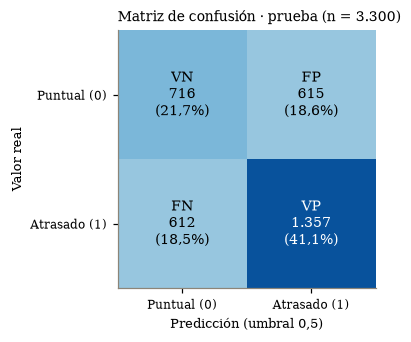

In [11]:
fig, ax = plt.subplots(figsize=(3.6, 3.0))
total = mc.sum()
ax.imshow(mc, cmap='Blues', vmin=0, vmax=mc.max() * 1.15)
etiquetas = [['VN', 'FP'], ['FN', 'VP']]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{etiquetas[i][j]}\n{num(mc[i, j])}\n({num(mc[i, j] / total * 100, 1)}%)', ha='center', va='center',
                fontsize=9, color='white' if mc[i, j] > mc.max() * 0.6 else 'black')
ax.set_xticks([0, 1], ['Puntual (0)', 'Atrasado (1)'])
ax.set_yticks([0, 1], ['Puntual (0)', 'Atrasado (1)'])
ax.set_xlabel('Predicción (umbral 0,5)')
ax.set_ylabel('Valor real')
ax.set_title(f'Matriz de confusión · prueba (n = {num(total)})')
ax.grid(False)
guardar('fig_2_matriz_confusion', fig)

#### Interpretación de la matriz de confusión y las métricas

| Métrica | Modelo | Línea base (todos atrasados) | Qué significa en el problema |
|---|---:|---:|---|
| Accuracy | 0,628 | 0,597 | Acierta el 62,8 % de los envíos: apenas 3,2 puntos más que no modelar |
| Precision | 0,688 | 0,597 | De los 1.972 envíos que el modelo alerta como atrasados, el 69 % lo está |
| Recall (sensibilidad) | 0,689 | 1,000 | Anticipa 1.357 de los 1.969 atrasos; 612 (31 %) llegan sin aviso |
| F1 | 0,689 | 0,747 | Balance entre precision y recall |
| Especificidad | 0,538 | 0,000 | Reconoce como puntuales solo 716 de los 1.331 envíos puntuales |

**La exactitud engaña.** Con 59,7 % de atrasos, 62,8 % de exactitud es una mejora modesta. Incluso el F1 del clasificador trivial (0,747) supera al del modelo, porque su recall es 1. En una clase positiva mayoritaria, el F1 favorece predecir "atrasado" siempre. Por eso se evalúa también la especificidad y, sobre todo, el AUC, que no depende del umbral.

**Errores en el contexto.**

- Un **falso negativo** (612) es un atraso que no se anticipa: el cliente no recibe aviso y la empresa no reacciona.
- Un **falso positivo** (615) es un envío puntual tratado como riesgoso: se gastan recursos de prevención innecesarios.

Con el umbral 0,5 ambos errores son casi iguales. Si para la empresa un atraso no anticipado cuesta más que una alerta innecesaria, convendría bajar el umbral para ganar recall a costa de precision. Esa decisión requiere conocer los costos y corresponde a S3.

### 4.2 Curva ROC y AUC

La **curva ROC** (*Receiver Operating Characteristic*) muestra, para todos los umbrales posibles, la tasa de verdaderos positivos (recall) frente a la tasa de falsos positivos (1 − especificidad). El **AUC** es la probabilidad de que un envío atrasado elegido al azar reciba una probabilidad predicha mayor que un envío puntual elegido al azar. Por eso no depende del umbral.

**Rangos de referencia** (Hosmer, Lemeshow y Sturdivant, 2013):

| AUC | Discriminación |
|---|---|
| 0,5 | Nula (azar) |
| 0,5 – 0,7 | Pobre |
| 0,7 – 0,8 | Aceptable |
| 0,8 – 0,9 | Excelente |
| ≥ 0,9 | Sobresaliente |

In [12]:
auc = roc_auc_score(y_test, p_test)
# Control: el AUC es la probabilidad de que un atrasado supere a un puntual (U de Mann–Whitney / (n1·n0))
rangos = stats.rankdata(p_test)
n1, n0 = int(y_test.sum()), int((y_test == 0).sum())
auc_rangos = (rangos[y_test.to_numpy() == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
assert np.isclose(auc, auc_rangos), 'El AUC de sklearn debe coincidir con el AUC por rangos.'

fpr, tpr, umbrales = roc_curve(y_test, p_test)
k_youden = np.argmax(tpr - fpr)
UMBRAL_YOUDEN = umbrales[k_youden]
y_youden = (p_test >= UMBRAL_YOUDEN).astype(int)
CATEGORIA_AUC = ('nula' if auc <= 0.5 else 'pobre' if auc < 0.7 else 'aceptable' if auc < 0.8
                 else 'excelente' if auc < 0.9 else 'sobresaliente')
umbral_tabla = pd.DataFrame({'umbral 0,5': metricas(y_test, y_pred),
                             f'umbral de Youden ({num(UMBRAL_YOUDEN, 3)})': metricas(y_test, y_youden)})
umbral_tabla.to_csv(TABLAS / 'metricas_umbrales.csv')
print(f'AUC = {num(auc, 4)} (control por rangos: {num(auc_rangos, 4)}) → discriminación {CATEGORIA_AUC}')
display(umbral_tabla.round(4))

AUC = 0,7139 (control por rangos: 0,7139) → discriminación aceptable


,"umbral 0,5","umbral de Youden (0,675)"
accuracy,0.6282,0.6515
precision,0.6881,0.9669
recall,0.6892,0.4307
f1,0.6887,0.5959
especificidad,0.5379,0.9782


### 4.3 Análisis crítico: ¿de dónde viene el desempeño?

S2 concluyó que la asociación del descuento con el atraso **existe solo por el segmento con descuento > 10**. Ese segmento está 100 % atrasado y coincide con los envíos 1 a 3.135 del archivo. Si el modelo hereda esa dependencia, su desempeño global mezcla dos situaciones muy distintas. Se evalúan cuatro variantes:

1. **Segmentos de la prueba:** el modelo principal, evaluado por separado en los envíos de prueba con descuento ≤ 10. En los de descuento > 10 todos son atrasados, por lo que el AUC no está definido; se informa el recall.
2. **Sin descuento:** el mismo flujo con solo peso, costo y compras previas.
3. **Casos completos:** se eliminan las filas con algún faltante, en lugar de imputarlas.
4. **Datos originales:** el mismo modelo ajustado sin los faltantes simulados, como referencia de lo que cuesta imputar.

In [13]:
def linea_base(y_real):
    # Exactitud del clasificador trivial que predice siempre la clase mayoritaria del subconjunto
    return max(y_real.mean(), 1 - y_real.mean())


def ajustar_y_evaluar(predictores, X_tr, X_te, y_tr, y_te, imputar=True):
    pasos = [SimpleImputer(strategy='median')] if imputar else []
    prep = make_pipeline(*pasos, StandardScaler())
    Xtr = pd.DataFrame(prep.fit_transform(X_tr[predictores]), columns=predictores, index=X_tr.index)
    Xte = pd.DataFrame(prep.transform(X_te[predictores]), columns=predictores, index=X_te.index)
    m = sm.Logit(y_tr, sm.add_constant(Xtr)).fit(disp=0)
    p = m.predict(sm.add_constant(Xte))
    return m, p, {'n_entrenamiento': len(y_tr), 'n_prueba': len(y_te), 'auc': roc_auc_score(y_te, p),
                  'accuracy': accuracy_score(y_te, (p >= UMBRAL).astype(int)), 'accuracy_linea_base': linea_base(y_te),
                  'pseudo_r2': m.prsquared,
                  **{f'or_{v}': np.exp(m.params[v]) if v in m.params else np.nan for v in PREDICTORES}}


variantes = {'principal (imputación por mediana)': {'n_entrenamiento': len(y_train), 'n_prueba': len(y_test), 'auc': auc,
                                                    'accuracy': tabla_metricas.loc['accuracy', 'modelo (umbral 0,5)'],
                                                    'accuracy_linea_base': linea_base(y_test),
                                                    'pseudo_r2': modelo.prsquared,
                                                    **{f'or_{v}': coeficientes.loc[v, 'or_1de'] for v in PREDICTORES}}}
# 1) Segmentos de la prueba según el descuento ORIGINAL (no imputado)
desc_test = df.loc[X_test.index, 'descuento_ofrecido']
bajo = desc_test <= 10
variantes['principal, prueba con descuento ≤ 10'] = {'n_prueba': int(bajo.sum()), 'auc': roc_auc_score(y_test[bajo], p_test[bajo]),
                                                     'accuracy': accuracy_score(y_test[bajo], y_pred[bajo]),
                                                     'accuracy_linea_base': linea_base(y_test[bajo]),
                                                     'tasa_atraso': y_test[bajo].mean(), 'pct_predicho_atrasado': y_pred[bajo].mean()}
recall_alto = y_pred[~bajo].mean()
# 2) Sin descuento
_, p_sin, variantes['sin descuento'] = ajustar_y_evaluar(['peso_gramos', 'costo_producto', 'compras_previas'],
                                                         X_train, X_test, y_train, y_test)
# 3) Casos completos: se eliminan las filas con algún faltante en entrenamiento y prueba
cc_tr, cc_te = X_train.notna().all(axis=1), X_test.notna().all(axis=1)
_, _, variantes['casos completos (dropna)'] = ajustar_y_evaluar(PREDICTORES, X_train[cc_tr], X_test[cc_te],
                                                                y_train[cc_tr], y_test[cc_te], imputar=False)
# 4) Datos originales sin faltantes simulados (mismas filas de entrenamiento y prueba)
_, _, variantes['datos originales (sin faltantes)'] = ajustar_y_evaluar(PREDICTORES, df.loc[X_train.index], df.loc[X_test.index],
                                                                        y_train, y_test, imputar=False)
sensibilidad = pd.DataFrame(variantes).T
sensibilidad.to_csv(TABLAS / 'sensibilidad_modelo.csv')
print(f'Prueba con descuento > 10: {num((~bajo).sum())} envíos, todos atrasados; el modelo los clasifica como atrasados '
      f'en el {num(recall_alto * 100, 1)}% de los casos (recall del segmento).')
display(sensibilidad.round(4))

Prueba con descuento > 10: 807 envíos, todos atrasados; el modelo los clasifica como atrasados en el 99,9% de los casos (recall del segmento).


,n_entrenamiento,n_prueba,auc,accuracy,accuracy_linea_base,pseudo_r2,or_peso_gramos,or_descuento_ofrecido,or_costo_producto,or_compras_previas,tasa_atraso,pct_predicho_atrasado
principal (imputación por mediana),7699.0,3300.0,0.7139,0.6282,0.5967,0.1790,0.7216,6.1891,0.8800,0.8788,NaN,NaN
"principal, prueba con descuento ≤ 10",NaN,2493.0,0.5205,0.5082,0.5339,NaN,NaN,NaN,NaN,NaN,0.4661,0.4677
sin descuento,7699.0,3300.0,0.6660,0.6167,0.5967,0.0665,0.5296,NaN,0.7886,0.8061,NaN,NaN
casos completos (dropna),6309.0,2651.0,0.7140,0.6273,0.6035,0.1897,0.7184,6.5615,0.8749,0.8727,NaN,NaN
datos originales (sin faltantes),7699.0,3300.0,0.7207,0.6352,0.5967,0.1862,0.7238,6.3445,0.8914,0.8711,NaN,NaN


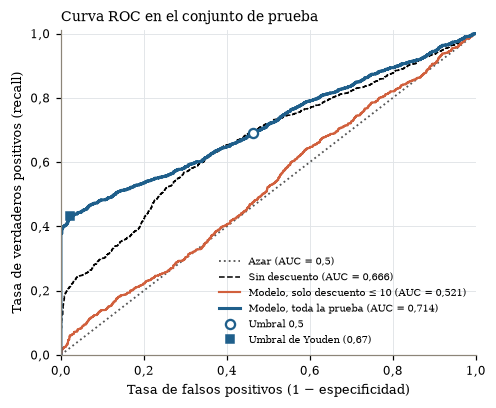

In [14]:
fig, ax = plt.subplots(figsize=(4.4, 3.6))
ax.plot([0, 1], [0, 1], color=GRIS, ls=':', lw=1.2, label='Azar (AUC = 0,5)')
f_b, t_b, _ = roc_curve(y_test[bajo], p_test[bajo])
f_s, t_s, _ = roc_curve(y_test, p_sin)
ax.plot(f_s, t_s, color='black', lw=1, ls='--', label=f"Sin descuento (AUC = {num(variantes['sin descuento']['auc'], 3)})")
ax.plot(f_b, t_b, color=TERRA, lw=1.4,
        label=f"Modelo, solo descuento ≤ 10 (AUC = {num(variantes['principal, prueba con descuento ≤ 10']['auc'], 3)})")
ax.plot(fpr, tpr, color=AZUL, lw=2, label=f'Modelo, toda la prueba (AUC = {num(auc, 3)})')
k05 = np.argmin(np.abs(umbrales - UMBRAL))
ax.plot(fpr[k05], tpr[k05], 'o', color=AZUL, ms=6, mfc='white', mew=1.5, label='Umbral 0,5')
ax.plot(fpr[k_youden], tpr[k_youden], 's', color=AZUL, ms=5, label=f'Umbral de Youden ({num(UMBRAL_YOUDEN, 2)})')
ax.set_xlabel('Tasa de falsos positivos (1 − especificidad)')
ax.set_ylabel('Tasa de verdaderos positivos (recall)')
ax.set_title('Curva ROC en el conjunto de prueba')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.01)
fmt = FuncFormatter(lambda v, _: num(v, 1))
ax.xaxis.set_major_formatter(fmt)
ax.yaxis.set_major_formatter(fmt)
ax.legend(loc='lower right', fontsize=6.8)
guardar('fig_3_curva_roc', fig)

#### Interpretación de la curva ROC, el AUC y el análisis crítico

**AUC = 0,714: discriminación aceptable** (rango 0,7–0,8), calculada con sklearn y verificada por rangos. Si se elige al azar un envío atrasado y uno puntual, el modelo asigna mayor probabilidad de atraso al atrasado en el 71 % de los casos.

**El desempeño viene casi por completo del segmento con descuento > 10.** La curva sube verticalmente hasta un recall de ≈ 0,40 sin falsos positivos. Esos son los 807 envíos de prueba con descuento > 10, todos atrasados, que el modelo reconoce en el 99,9 % de los casos. Por eso el umbral de Youden (0,675) logra una precision de 0,97 y una especificidad de 0,98, pero solo con recall 0,43: detecta casi únicamente ese segmento.

| Variante | AUC prueba | Accuracy | Línea base | Lectura |
|---|---:|---:|---:|---|
| Modelo, toda la prueba | 0,714 | 0,628 | 0,597 | Aceptable |
| Modelo, solo descuento ≤ 10 (2.493 envíos) | **0,521** | 0,508 | 0,534 | ≈ azar; **peor que predecir siempre "puntual"** |
| Sin descuento | 0,666 | 0,617 | 0,597 | Pobre |
| Casos completos (pierde 18 % de envíos) | 0,714 | 0,627 | 0,604 | Igual al imputado |
| Datos originales sin faltantes | 0,721 | 0,635 | 0,597 | Referencia |

Fuera del segmento > 10, que es el 76 % de los envíos, el modelo **no discrimina** (AUC 0,52), confirmando lo que S2 encontró con las correlaciones: con descuento ≤ 10, la del descuento es −0,014 y solo el peso conserva una asociación débil. El AUC global de 0,71 no describe un modelo útil para todos los envíos, sino uno que reconoce un bloque de registros con características propias (ids 1 a 3.135).

**La imputación no compromete el modelo.** Frente a los datos originales, imputar con la mediana cuesta 0,007 de AUC y atenúa levemente el OR del descuento (6,19 frente a 6,34), como se espera de una imputación constante. Los casos completos dan el mismo AUC, pero con 18 % menos envíos. La mediana del entrenamiento resultó una regla adecuada bajo MCAR.

### 4.4 Validación cruzada estratificada (10 particiones)

La partición 70/30 entrega **una sola** estimación del desempeño, que depende de qué envíos quedaron en la prueba. La **validación cruzada estratificada de *k* particiones** divide el entrenamiento en 10 partes con la misma proporción de atraso. Entrena con 9 y evalúa en la restante, rotando 10 veces. La imputación y la estandarización se reajustan **dentro de cada partición** (*pipeline*), para que la parte de validación nunca influya en ellas. Así se obtienen la media y la **variabilidad** de cada métrica. El conjunto de prueba se reserva como evaluación final.

In [15]:
from sklearn.metrics import make_scorer
from sklearn.model_selection import cross_validate

flujo = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(C=np.inf, max_iter=1_000))
METRICAS_CV = {'auc': 'roc_auc', 'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall',
               'especificidad': make_scorer(recall_score, pos_label=0)}
cv_res = cross_validate(flujo, X_train, y_train, cv=CV10, scoring=METRICAS_CV)
por_fold = pd.DataFrame({m: cv_res[f'test_{m}'] for m in METRICAS_CV}, index=pd.RangeIndex(1, 11, name='fold'))
tasas_fold = [y_train.iloc[val].mean() for _, val in CV10.split(X_train, y_train)]
assert max(abs(t - y_train.mean()) for t in tasas_fold) < 0.01, 'Las particiones deben conservar la tasa de atraso.'
en_prueba = {'auc': auc, **{m: tabla_metricas.loc[m, 'modelo (umbral 0,5)'] for m in METRICAS_CV if m != 'auc'}}
resumen_cv = pd.DataFrame({'media': por_fold.mean(), 'de': por_fold.std(ddof=1), 'minimo': por_fold.min(),
                           'maximo': por_fold.max(), 'prueba': pd.Series(en_prueba)})
resumen_cv['prueba_dentro_del_rango'] = resumen_cv['prueba'].between(resumen_cv['minimo'], resumen_cv['maximo'])
assert resumen_cv.loc['auc', 'prueba_dentro_del_rango'], 'El AUC de prueba debería caer en el rango de las particiones.'
por_fold.to_csv(TABLAS / 'validacion_cruzada_por_fold.csv')
resumen_cv.to_csv(TABLAS / 'validacion_cruzada_resumen.csv')
display(resumen_cv.round(4))

,media,de,minimo,maximo,prueba,prueba_dentro_del_rango
auc,0.7137,0.0101,0.6983,0.7276,0.7139,True
accuracy,0.6345,0.0130,0.6104,0.6571,0.6282,True
precision,0.6952,0.0134,0.6688,0.7112,0.6881,True
recall,0.6905,0.0188,0.6609,0.7190,0.6892,True
especificidad,0.5517,0.0309,0.4952,0.5839,0.5379,True


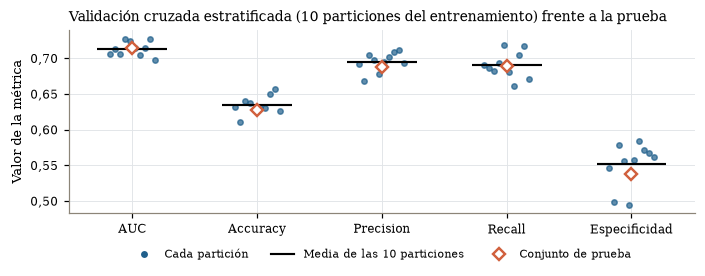

In [16]:
fig, ax = plt.subplots(figsize=(ANCHO, 2.4))
for j, m in enumerate(METRICAS_CV):
    x = j + np.linspace(-0.18, 0.18, len(por_fold))
    ax.plot(x, por_fold[m], 'o', color=AZUL, ms=3.5, alpha=0.7)
    ax.hlines(resumen_cv.loc[m, 'media'], j - 0.28, j + 0.28, color='black', lw=1.4)
    ax.plot(j, resumen_cv.loc[m, 'prueba'], 'D', color=TERRA, ms=6, mfc='white', mew=1.6)
ax.set_xticks(range(len(METRICAS_CV)), ['AUC', 'Accuracy', 'Precision', 'Recall', 'Especificidad'])
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: num(v, 2)))
ax.set_ylabel('Valor de la métrica')
ax.set_title('Validación cruzada estratificada (10 particiones del entrenamiento) frente a la prueba')
ax.legend([Line2D([], [], color=AZUL, marker='o', ls='', ms=3.5), Line2D([], [], color='black', lw=1.4),
           Line2D([], [], color=TERRA, marker='D', ls='', ms=6, mfc='white', mew=1.6)],
          ['Cada partición', 'Media de las 10 particiones', 'Conjunto de prueba'], loc='upper center',
          bbox_to_anchor=(0.5, -0.14), fontsize=7.5, ncol=3)
guardar('fig_4_validacion_cruzada', fig)

#### Interpretación de la validación cruzada

| Métrica | Media CV ± DE | Rango (10 particiones) | Prueba |
|---|---:|---:|---:|
| AUC | 0,714 ± 0,010 | [0,698; 0,728] | 0,714 |
| Accuracy | 0,635 ± 0,013 | [0,610; 0,657] | 0,628 |
| Precision | 0,695 ± 0,013 | [0,669; 0,711] | 0,688 |
| Recall | 0,691 ± 0,019 | [0,661; 0,719] | 0,689 |
| Especificidad | 0,552 ± 0,031 | [0,495; 0,584] | 0,538 |

- **La estimación es estable.** El AUC varía apenas ±0,010 entre particiones y el de la prueba coincide con la media de la validación cruzada. Las cinco métricas de la prueba caen dentro del rango de las particiones: el resultado de la partición 70/30 no fue un caso afortunado ni desfavorable.
- **No hay sobreajuste.** El modelo rinde igual en datos no vistos que en la validación interna, como se espera de una regresión logística con cuatro predictores y más de 7.000 envíos.
- **La especificidad es la métrica más inestable** (DE de 0,031, entre 0,50 y 0,58): la capacidad de reconocer envíos puntuales depende de qué envíos quedan en cada partición. La conclusión del análisis crítico se mantiene: con 0,71 el AUC es aceptable, pero el modelo distingue mal a los puntuales.

### 4.5 Búsqueda de hiperparámetros (GridSearchCV)

La regresión logística tiene pocos hiperparámetros: la **penalización** de los coeficientes (su intensidad, 1/C, y su tipo, L2 o L1) y la **ponderación de clases**. Se buscan con `GridSearchCV`, que prueba **todas** las combinaciones de una grilla pequeña con la misma validación cruzada de 10 particiones y escoge la de mayor AUC:

- C entre 10⁻³ y 10³: valores bajos implican una penalización fuerte, que acerca los coeficientes a 0;
- penalización L2 (*ridge*, `l1_ratio = 0`) o L1 (*lasso*, `l1_ratio = 1`);
- `class_weight` sin ponderar o `balanced`, que pondera más a la clase minoritaria (puntuales).

Con tres hiperparámetros discretos, la búsqueda exhaustiva es barata y determinista, así que `RandomizedSearchCV` no aportaría. El modelo con el mejor AUC se compara con el modelo sin penalizar en el conjunto de prueba, incluyendo la **calibración** mediante el puntaje de Brier: el error cuadrático medio entre la probabilidad predicha y el resultado observado, donde menor es mejor.

In [17]:
from sklearn.metrics import brier_score_loss
from sklearn.model_selection import GridSearchCV

flujo_grid = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                           LogisticRegression(solver='liblinear', max_iter=1_000))
GRILLA = {'logisticregression__C': np.logspace(-3, 3, 13), 'logisticregression__l1_ratio': [0, 1],
          'logisticregression__class_weight': [None, 'balanced']}
busqueda = GridSearchCV(flujo_grid, GRILLA, cv=CV10, scoring='roc_auc').fit(X_train, y_train)   # reajusta solo en entrenamiento
mejor = busqueda.best_estimator_
sin_penalizar = flujo.fit(X_train, y_train)


def evaluar(estimador, nombre, auc_cv):
    p = estimador.predict_proba(X_test)[:, 1]
    lr = estimador[-1]
    return {'modelo': nombre, 'auc_cv': auc_cv, 'auc_prueba': roc_auc_score(y_test, p),
            'brier_prueba': brier_score_loss(y_test, p), 'accuracy': accuracy_score(y_test, p >= UMBRAL),
            'recall': recall_score(y_test, p >= UMBRAL), 'especificidad': recall_score(y_test, p >= UMBRAL, pos_label=0),
            'p_min': p.min(), 'p_max': p.max(), **{f'coef_{v}': c for v, c in zip(PREDICTORES, lr.coef_[0])}}


bp = busqueda.best_params_
comparacion_grid = pd.DataFrame([
    evaluar(sin_penalizar, 'sin penalizar (modelo principal)', resumen_cv.loc['auc', 'media']),
    evaluar(mejor, f"mejor de la grilla: C = {bp['logisticregression__C']:g}, "
                   f"{'L1' if bp['logisticregression__l1_ratio'] == 1 else 'L2'}, "
                   f"class_weight = {bp['logisticregression__class_weight']}", busqueda.best_score_),
]).set_index('modelo')
resultados_grid = pd.DataFrame(busqueda.cv_results_)
auc_por_c = (resultados_grid.groupby('param_logisticregression__C')['mean_test_score'].max().rename('auc_cv_max'))
balanceado = resultados_grid[resultados_grid['param_logisticregression__class_weight'].astype(str) == 'balanced']
comparacion_grid.to_csv(TABLAS / 'busqueda_hiperparametros.csv')
auc_por_c.to_csv(TABLAS / 'busqueda_auc_por_c.csv')
print(f'{len(resultados_grid)} combinaciones × 10 particiones. Mejor: {bp} (AUC CV = {num(busqueda.best_score_, 4)})')
print(f"Mejor AUC CV con class_weight = 'balanced': {num(balanceado['mean_test_score'].max(), 4)}")
display(comparacion_grid.round(4).T)
display(auc_por_c.round(4).to_frame().T)

52 combinaciones × 10 particiones. Mejor: {'logisticregression__C': np.float64(0.001), 'logisticregression__class_weight': None, 'logisticregression__l1_ratio': 0} (AUC CV = 0,7210)
Mejor AUC CV con class_weight = 'balanced': 0,7208


modelo,sin penalizar (modelo principal),"mejor de la grilla: C = 0.001, L2, class_weight = None"
auc_cv,0.7137,0.7210
auc_prueba,0.7139,0.7227
brier_prueba,0.1972,0.2039
accuracy,0.6282,0.6461
recall,0.6892,0.6800
especificidad,0.5379,0.5958
p_min,0.1867,0.3012
p_max,0.9995,0.9227
coef_peso_gramos,-0.3263,-0.2574
coef_descuento_ofrecido,1.8228,0.5052


param_logisticregression__C,0.001000,0.003162,0.010000,0.031623,0.100000,0.316228,1.000000,3.162278,10.000000,31.622777,100.000000,316.227766,1000.000000
auc_cv_max,0.721,0.7202,0.7183,0.716,0.7147,0.714,0.7138,0.7137,0.7137,0.7137,0.7137,0.7137,0.7137


#### Interpretación de la búsqueda de hiperparámetros

| Modelo | AUC CV | AUC prueba | Brier prueba | Accuracy | Especificidad | Coeficiente del descuento |
|---|---:|---:|---:|---:|---:|---:|
| Sin penalizar (principal) | 0,714 | 0,714 | **0,197** | 0,628 | 0,538 | 1,82 |
| Mejor de la grilla (C = 0,001, L2) | **0,721** | **0,723** | 0,204 | 0,646 | 0,596 | 0,51 |

- **La mejora es pequeña y tiene un costo.** La grilla elige la penalización **más fuerte** probada. Gana 0,007 de AUC en validación cruzada (menos de una DE entre particiones) y 0,009 en la prueba. A cambio, **empeora la calibración**: el Brier sube de 0,197 a 0,204 y las probabilidades quedan comprimidas entre 0,30 y 0,92, cuando antes iban de 0,19 a 1,00. Además, los coeficientes penalizados están sesgados hacia 0, así que sus odds ratios y valores *p* no son interpretables. Para C ≥ 1 el AUC no cambia (0,714): el modelo sin penalizar ya es el óptimo de esa zona.
- **Por qué gana una penalización tan fuerte.** La penalización reduce sobre todo el coeficiente del descuento, que pasa de 1,82 a 0,51, mientras el del peso casi no cambia (de −0,33 a −0,26). Así el peso gana importancia relativa en el ordenamiento de los envíos, y el peso es justamente el único predictor que discrimina dentro del segmento con descuento ≤ 10. Es un **síntoma de mala especificación**: un término lineal en el descuento no representa bien su efecto umbral, todo atrasado sobre 10 y casi sin efecto bajo 10. La solución no es penalizar más, sino especificar ese efecto, con un modelo por segmento o una interacción.
- **La ponderación de clases no mejora la discriminación** (AUC CV 0,721 con `balanced`): solo mueve el equilibrio entre recall y especificidad, igual que cambiar el umbral.

**Decisión.** Se conserva el modelo sin penalizar de la sección 3 para la inferencia: coeficientes, odds ratios y *p*. La búsqueda queda como diagnóstico para S3.

In [18]:
metadatos = dict(semilla=SEMILLA, flujo_faltantes='SeedSequence(SEMILLA).spawn(8)[7]', tasa_mcar=TASA_MCAR,
                 particion=dict(test_size=0.30, stratify=TARGET, random_state=SEMILLA), predictores=PREDICTORES,
                 umbral=UMBRAL, sha256_datos=HUELLA_DATOS, versiones=VERSIONES,
                 sha256_lock=hashlib.sha256((REPO / 'uv.lock').read_bytes().replace(b'\r\n', b'\n')).hexdigest())
(TABLAS / 'metadatos_ejecucion.json').write_text(json.dumps(metadatos, ensure_ascii=False, indent=2), encoding='utf-8')
assert hashlib.sha256(DATOS.read_bytes()).hexdigest() == HUELLA_DATOS, 'El CSV original no debe modificarse.'
print('Metadatos registrados en outputs/tablas/metadatos_ejecucion.json')

Metadatos registrados en outputs/tablas/metadatos_ejecucion.json


## 5. Síntesis y reflexión

**Integración de S1 y S2.**

- **S1 aportó:**
  - el diagnóstico de calidad: sin faltantes, lo que obligó a simularlos de forma MCAR para ensayar la imputación, y extremos válidos;
  - la asimetría que justificó imputar con la mediana;
  - las correlaciones que ordenaron los candidatos;
  - los contrastes que descartaron la modalidad.
- **RFE** confirmó el orden de importancia (descuento, peso, compras previas y costo). Al ampliar los candidatos, propuso llamadas e importancia con una ganancia de AUC menor que la variabilidad entre particiones; la selección analítica las descarta por temporalidad o por evidencia débil.
- **S2 aportó:**
  - IC *bootstrap* que confirmaron el signo de las cuatro correlaciones;
  - escenarios de sensibilidad que separaron un predictor robusto (peso) de otros que dependen del segmento con descuento > 10;
  - evidencia para conservar los outliers: la winsorización no cambió nada y la exclusión IQR cambia la población;
  - el hallazgo del bloque 1–3.135, que obligó a excluir el identificador por fuga de información.

**Evaluación del modelo.** La regresión logística con peso, descuento, costo y compras previas no presenta multicolinealidad (VIF ≤ 1,25). Sus cuatro OR tienen la dirección esperada y son significativos, y alcanza un **AUC de 0,714 (aceptable)** en la prueba, igual a la media de la validación cruzada de 10 particiones (0,714 ± 0,010). El desempeño práctico es modesto:

- la exactitud (0,628) supera en solo 3 puntos a la línea base, y la especificidad es 0,54;
- el AUC proviene casi entero del segmento con descuento > 10, que el modelo identifica en 99,9 %;
- en el 76 % restante de los envíos discrimina como el azar (AUC 0,52).

El modelo **reproduce el hallazgo de S2 más que resolver el problema de anticipar atrasos**.

**Mejoras metodológicas para S3.**

1. **Verificar la procedencia del bloque 1–3.135** antes de usarlo para entrenar. Si corresponde a otro período, sistema o a datos sintéticos, debe tratarse como un segmento aparte o excluirse, documentándolo.
2. **Modelar por segmento de descuento**, o con una interacción descuento × segmento. Dentro de descuento > 10 no hay nada que predecir; el esfuerzo debe concentrarse en el segmento ≤ 10.
3. **Ampliar la especificación en el segmento ≤ 10:**
   - términos no lineales para el peso bimodal (tramos o *splines*);
   - variables categóricas que S1 no descartó, como importancia (E2) o bodega;
   - reevaluar la temporalidad de las llamadas.
4. **Validación cruzada anidada** para comparar el modelo segmentado con el actual sin sesgar la selección. La validación cruzada simple (AUC 0,714 ± 0,010) ya mostró que la estimación es estable, y la búsqueda de hiperparámetros, que penalizar no corrige la mala especificación del descuento.
5. **Elegir el umbral según el costo** de falsos negativos y falsos positivos, y revisar la **calibración** de las probabilidades antes de usarlas en decisiones operativas.